<a href="https://colab.research.google.com/github/juansepq2017-sys/Proyecto-Progra-2/blob/punto-8%2C9---visualizaciones-y-conclusiones/proyecto_creditos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto Programación II — Análisis de Créditos y Datos Demográficos

**Integrantes:** Juan Sebastian Castro Castellanos · Juan Sebastian Pardo Quintero · Andres Felipe Gomez Bejarano · Juan Esteban Gil

Dataset: `DATASET_proyecto_dic.xlsx` — solicitudes de crédito con variables demográficas, financieras y de vivienda.

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 1. Carga e inspección inicial de los datos

In [7]:
from google.colab import drive
import pandas as pd

# Montar Google Drive (si ya está montado, no pasa nada)
drive.mount('/content/drive')

# Leer tu archivo de Excel
ruta_excel = '/content/drive/MyDrive/proyecto programacion /DATASET_proyecto_dic.xlsx'
df = pd.read_excel(ruta_excel)
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,Column1,Age,Sex,Job,Housing,Saving Account,Checking account,Credit amount,Duration,Purpose
0,0,67,male,2,own,NaN,little,1169,6,radio/TV
1,1,22,female,2,own,little,moderate,5951,48,radio/TV
2,2,49,male,1,own,little,NaN,2096,12,education
3,3,45,male,2,free,little,little,7882,42,furniture/equipment
4,4,53,male,2,free,little,little,4870,24,car


In [8]:
print("Tamaño del conjunto (filas, columnas):", df.shape)
df.info()

Tamaño del conjunto (filas, columnas): (1000, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Column1           1000 non-null   int64 
 1   Age               1000 non-null   int64 
 2   Sex               1000 non-null   object
 3   Job               1000 non-null   int64 
 4   Housing           1000 non-null   object
 5   Saving Account    817 non-null    object
 6   Checking account  606 non-null    object
 7   Credit amount     1000 non-null   int64 
 8   Duration          1000 non-null   int64 
 9   Purpose           1000 non-null   object
dtypes: int64(5), object(5)
memory usage: 78.3+ KB


### Tipos de variables

In [9]:
numericas = df.select_dtypes(include="number").columns.tolist()
categoricas = df.select_dtypes(exclude="number").columns.tolist()
print("Numéricas:", numericas)
print("Categóricas:", categoricas)

Numéricas: ['Column1', 'Age', 'Job', 'Credit amount', 'Duration']
Categóricas: ['Sex', 'Housing', 'Saving Account', 'Checking account', 'Purpose']


| Tipo | Variables |
|---|---|
| Numérica continua | `Credit amount` |
| Numérica discreta | `Age`, `Duration` |
| Categórica ordinal | `Job` (codificada 0–3), `Saving Account`, `Checking account` |
| Categórica nominal | `Sex`, `Housing`, `Purpose` |
| Índice (sin valor analítico) | `Column1` |

### Descripción estadística

In [10]:
df.describe()

,Column1,Age,Job,Credit amount,Duration
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,499.500000,35.546000,1.904000,3271.258000,20.903000
std,288.819436,11.375469,0.653614,2822.736876,12.058814
min,0.000000,19.000000,0.000000,250.000000,4.000000
25%,249.750000,27.000000,2.000000,1365.500000,12.000000
50%,499.500000,33.000000,2.000000,2319.500000,18.000000
75%,749.250000,42.000000,2.000000,3972.250000,24.000000
max,999.000000,75.000000,3.000000,18424.000000,72.000000


In [11]:
df.describe(exclude="number")

,Sex,Housing,Saving Account,Checking account,Purpose
count,1000,1000,817,606,1000
unique,2,3,4,3,8
top,male,own,little,little,car
freq,690,713,603,274,337


## 2. Manejo de datos faltantes

In [12]:
faltantes = pd.DataFrame({
    "faltantes": df.isna().sum(),
    "porcentaje": (df.isna().mean() * 100).round(1)
})
faltantes[faltantes["faltantes"] > 0]

,faltantes,porcentaje
Saving Account,183,18.3
Checking account,394,39.4


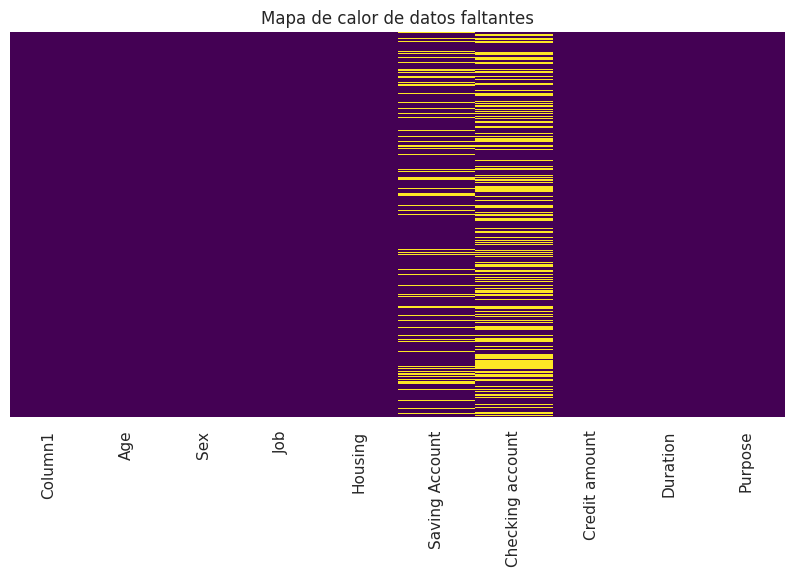

In [13]:
plt.figure(figsize=(10, 5))
sns.heatmap(df.isna(), cbar=False, cmap="viridis", yticklabels=False)
plt.title("Mapa de calor de datos faltantes")
plt.show()

In [14]:
print("Filas con al menos un faltante:", df.isna().any(axis=1).sum())

Filas con al menos un faltante: 478


**Decisión: imputar con la categoría `"unknown"`, no eliminar.**

- `Checking account` tiene **39,4 %** de faltantes y `Saving Account` **18,3 %**. Si elimináramos filas perderíamos **478 registros (47,8 %)**, casi la mitad de la base.
- Imputar con la moda (`little`) inflaría artificialmente esa categoría y distorsionaría los análisis por ahorro/cuenta.
- Ambas son variables categóricas: crear la categoría `"unknown"` conserva todos los registros y deja explícito que la información no fue reportada (lo cual puede ser informativo en sí mismo).

In [15]:
df[["Saving Account", "Checking account"]] = df[["Saving Account", "Checking account"]].fillna("unknown")
df.isna().sum()

,0
Column1,0
Age,0
Sex,0
Job,0
Housing,0
Saving Account,0
Checking account,0
Credit amount,0
Duration,0
Purpose,0


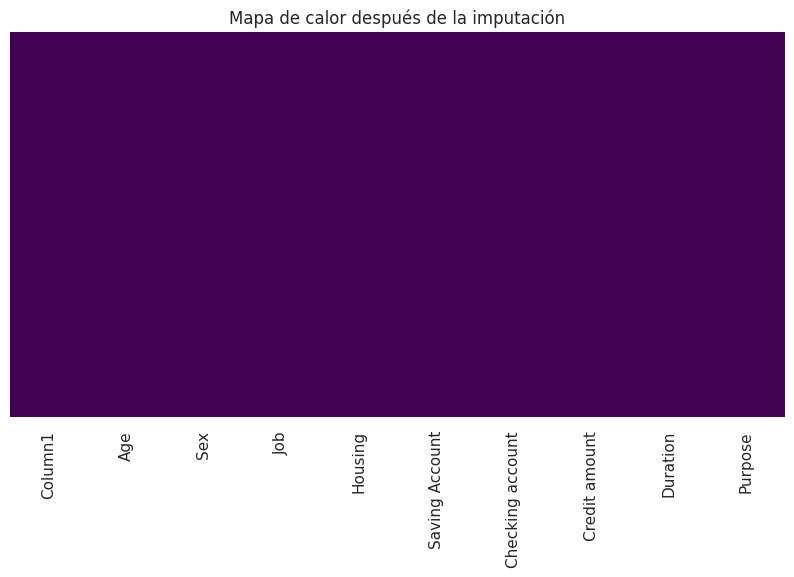

In [16]:
plt.figure(figsize=(10, 5))
sns.heatmap(df.isna(), cbar=False, cmap="viridis", yticklabels=False)
plt.title("Mapa de calor después de la imputación")
plt.show()

In [17]:
# Nombres de columnas: estandarizar a minúsculas con guion bajo
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")
df.columns.tolist()

['column1',
 'age',
 'sex',
 'job',
 'housing',
 'saving_account',
 'checking_account',
 'credit_amount',
 'duration',
 'purpose']

### 3. Boxplot de Outliers


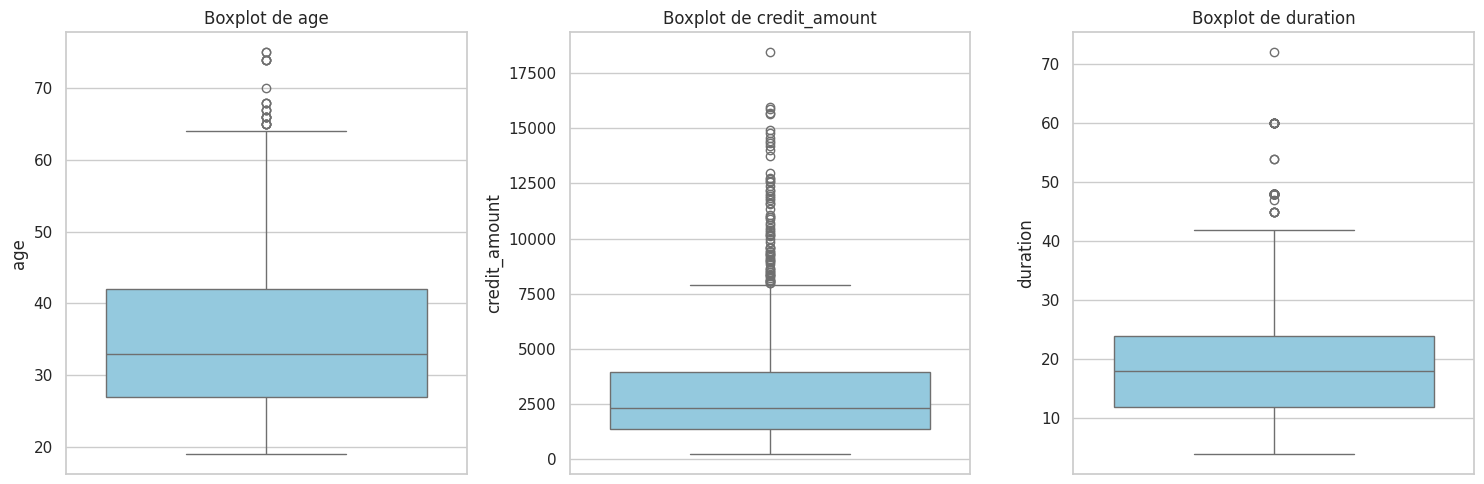

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, col in zip(axes, ["age", "credit_amount", "duration"]):
    sns.boxplot(y=df[col], ax=ax, color="skyblue")
    ax.set_title(f"Boxplot de {col}")
plt.tight_layout()
plt.show()

## 4. Tratamiento de valores inconsistentes en texto y duplicados

In [19]:
# La columna column1 es solo un índice de posición: no aporta información
df = df.drop(columns="column1")

In [20]:
# Valores de texto: quitar espacios y pasar a minúsculas
cols_texto = df.select_dtypes(exclude="number").columns
for col in cols_texto:
    antes = df[col].nunique()
    df[col] = df[col].str.strip().str.lower()
    print(f"{col}: {antes} -> {df[col].nunique()} categorías | {sorted(df[col].unique())}")

sex: 2 -> 2 categorías | ['female', 'male']
housing: 3 -> 3 categorías | ['free', 'own', 'rent']
saving_account: 5 -> 5 categorías | ['little', 'moderate', 'quite rich', 'rich', 'unknown']
checking_account: 4 -> 4 categorías | ['little', 'moderate', 'rich', 'unknown']
purpose: 8 -> 8 categorías | ['business', 'car', 'domestic appliances', 'education', 'furniture/equipment', 'radio/tv', 'repairs', 'vacation/others']


Los valores de texto ya eran consistentes: después de limpiar espacios y mayúsculas el número de categorías no cambia, así que no había variantes como `Male`/`male ` duplicadas.

In [21]:
print("Filas duplicadas:", df.duplicated().sum())
df = df.drop_duplicates()
print("Tamaño final:", df.shape)

Filas duplicadas: 0
Tamaño final: (1000, 9)


No hay registros duplicados en la base, por lo que no se elimina ninguna fila.

### 5. Creacion de variables.

In [22]:
# 1) Cuota mensual aproximada (sin intereses)
df["cuota_mensual"] = (df["credit_amount"] / df["duration"]).round(2)

# 2) Grupo de edad
df["grupo_edad"] = pd.cut(df["age"], bins=[18, 25, 35, 50, 100],
                          labels=["18-25", "26-35", "36-50", "51+"])

# 3) Tipo de plazo
df["tipo_plazo"] = pd.cut(df["duration"], bins=[0, 12, 36, 100],
                          labels=["corto (≤12m)", "medio (13-36m)", "largo (>36m)"])

#Mostrar nuevas columnas.
df[["credit_amount", "duration", "cuota_mensual", "age", "grupo_edad", "tipo_plazo"]].head()

,credit_amount,duration,cuota_mensual,age,grupo_edad,tipo_plazo
0,1169,6,194.83,67,51+,corto (≤12m)
1,5951,48,123.98,22,18-25,largo (>36m)
2,2096,12,174.67,49,36-50,corto (≤12m)
3,7882,42,187.67,45,36-50,largo (>36m)
4,4870,24,202.92,53,51+,medio (13-36m)


### 6. Filtrado y condiciones

# 6.1 Creditos mayores a 10.000

In [23]:
grandes = df[df["credit_amount"] > 10000]
print("Cantidad:", len(grandes))
print("Duración promedio:", round(grandes["duration"].mean(), 1), "meses")
grandes["purpose"].value_counts().head(3)

Cantidad: 40
Duración promedio: 40.2 meses


,count
purpose,
car,20
business,5
vacation/others,5


## 6.2 Jóvenes (≤ 25 años) que viven en arriendo

In [24]:
jovenes = df[df["age"] <= 25]
print("Jóvenes:", len(jovenes))
print("% jóvenes en arriendo:", round((jovenes["housing"] == "rent").mean() * 100, 1))
print("% general en arriendo:", round((df["housing"] == "rent").mean() * 100, 1))

Jóvenes: 190
% jóvenes en arriendo: 41.6
% general en arriendo: 17.9


## 6.3 Créditos de plazo muy largo (≥ 48 meses)

In [25]:
largos = df[df["duration"] >= 48]
print("Cantidad:", len(largos))
print("Monto promedio:", round(largos["credit_amount"].mean(), 0))
print("Monto promedio general:", round(df["credit_amount"].mean(), 0))

Cantidad: 64
Monto promedio: 8064.0
Monto promedio general: 3271.0


#6.4 Mayores de 60 años

In [26]:
mayores = df[df["age"] > 60]
print("Cantidad:", len(mayores))
mayores["housing"].value_counts()

Cantidad: 45


,count
housing,
own,30
free,12
rent,3


# 6.5 Trabajadores altamente cualificados (job = 3)

In [27]:
cualificados = df[df["job"] == 3]
print("Cantidad:", len(cualificados))
print("Monto promedio:", round(cualificados["credit_amount"].mean(), 0))
cualificados["purpose"].value_counts().head(3)

Cantidad: 148
Monto promedio: 5435.0


,count
purpose,
car,69
radio/tv,26
furniture/equipment,21


# 7 Agrupacion con groupby

# 7.1 Monto promedio por proposito

In [28]:
df.groupby("purpose")["credit_amount"].agg(["count", "mean", "median"]).round(0).sort_values("mean", ascending=False)

,count,mean,median
purpose,,,
vacation/others,12,8209.0,6948.0
business,97,4158.0,3161.0
car,337,3768.0,2679.0
furniture/equipment,181,3067.0,2578.0
education,59,2879.0,1597.0
repairs,22,2728.0,1749.0
radio/tv,280,2488.0,1890.0
domestic appliances,12,1498.0,1249.0


## 7.2 Monto promedio por nivel laboral

In [29]:
df.groupby("job")["credit_amount"].mean().round(0)

,credit_amount
job,
0,2745.0
1,2359.0
2,3071.0
3,5435.0


# 7.3 Comparación por sexo

In [30]:
df.groupby("sex")[["credit_amount", "duration", "age"]].mean().round(1)

,credit_amount,duration,age
sex,,,
female,2877.8,19.4,32.8
male,3448.0,21.6,36.8


# 7.4 Edad promedio por tipo de vivienda

In [31]:
df.groupby("housing")["age"].mean().round(1)

,age
housing,
free,43.8
own,35.6
rent,30.4


# 7.5 Cuota mensual por grupo de edad

In [32]:
df.groupby("grupo_edad", observed=True)[["credit_amount", "duration", "cuota_mensual"]].mean().round(0)

,credit_amount,duration,cuota_mensual
grupo_edad,,,
18-25,3003.0,21.0,153.0
26-35,3299.0,21.0,161.0
36-50,3395.0,21.0,176.0
51+,3297.0,20.0,192.0


### 8. Visualizaciones.

8.1 Distribución del monto del crédito

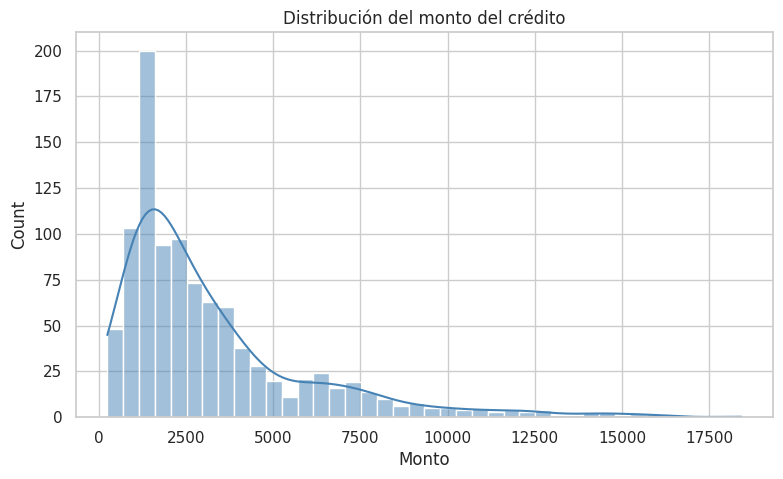

In [33]:
plt.figure(figsize=(9, 5))
sns.histplot(df["credit_amount"], bins=40, kde=True, color="steelblue")
plt.title("Distribución del monto del crédito")
plt.xlabel("Monto")
plt.show()

8.2 Monto vs. duración

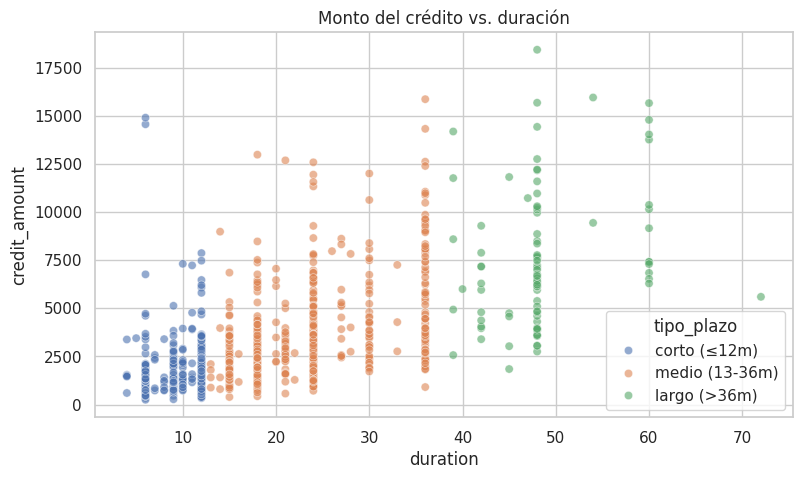

Correlación: 0.62


In [34]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x="duration", y="credit_amount", hue="tipo_plazo", alpha=0.6)
plt.title("Monto del crédito vs. duración")
plt.show()
print("Correlación:", round(df["credit_amount"].corr(df["duration"]), 2))

8.3 Cantidad de créditos por propósito

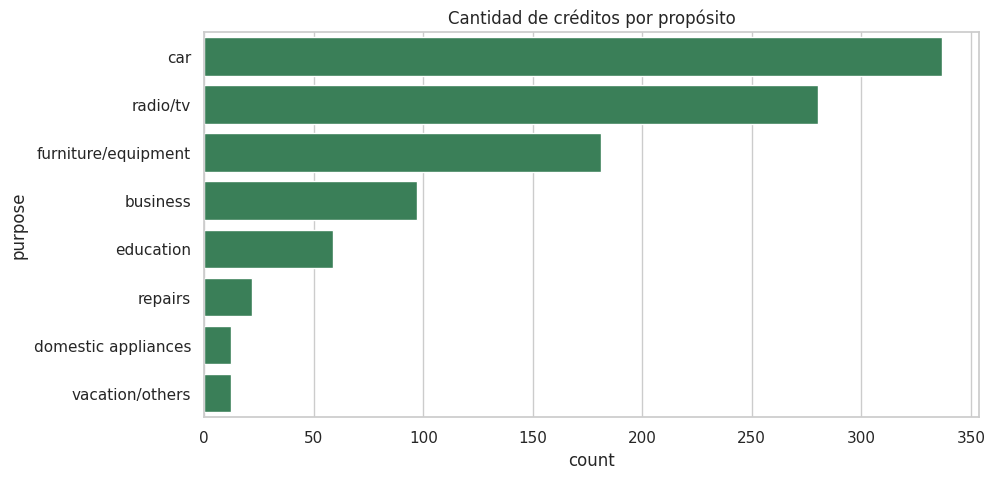

In [36]:
plt.figure(figsize=(10, 5))
orden = df["purpose"].value_counts().index
sns.countplot(data=df, y="purpose", order=orden, color="seagreen")
plt.title("Cantidad de créditos por propósito")
plt.show()

8.4 Monto por tipo de vivienda

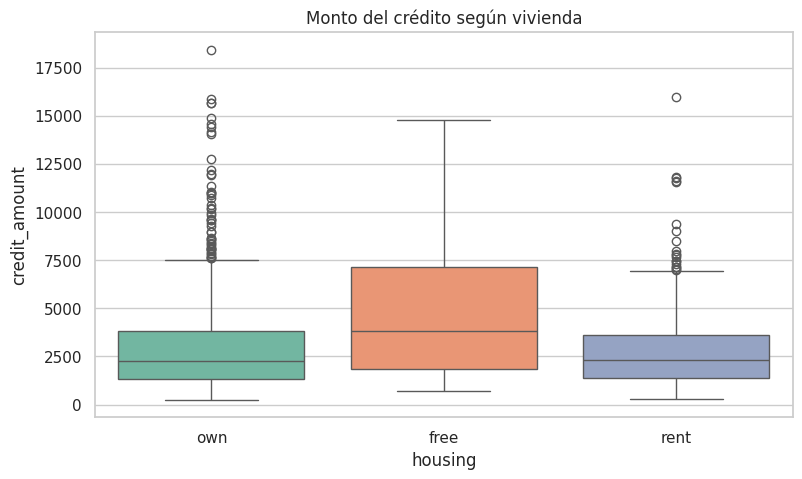

In [37]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="housing", y="credit_amount", palette="Set2", hue="housing", legend=False)
plt.title("Monto del crédito según vivienda")
plt.show()

8.5 Mapa de correlación

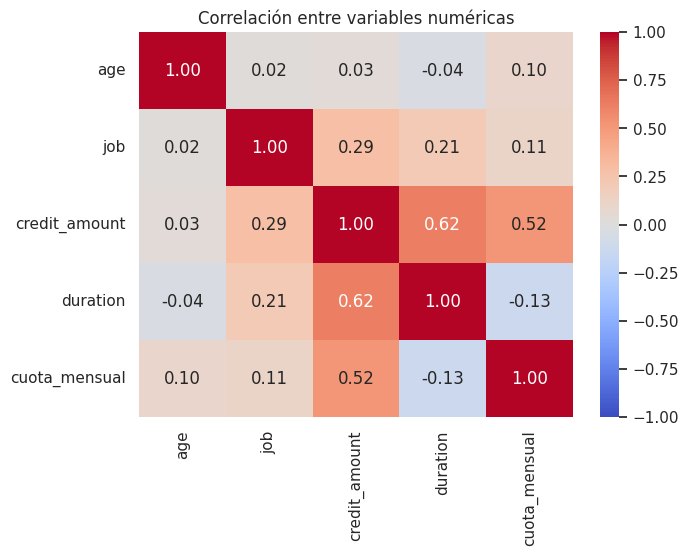

In [38]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[["age", "job", "credit_amount", "duration", "cuota_mensual"]].corr(),
            annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación entre variables numéricas")
plt.show()

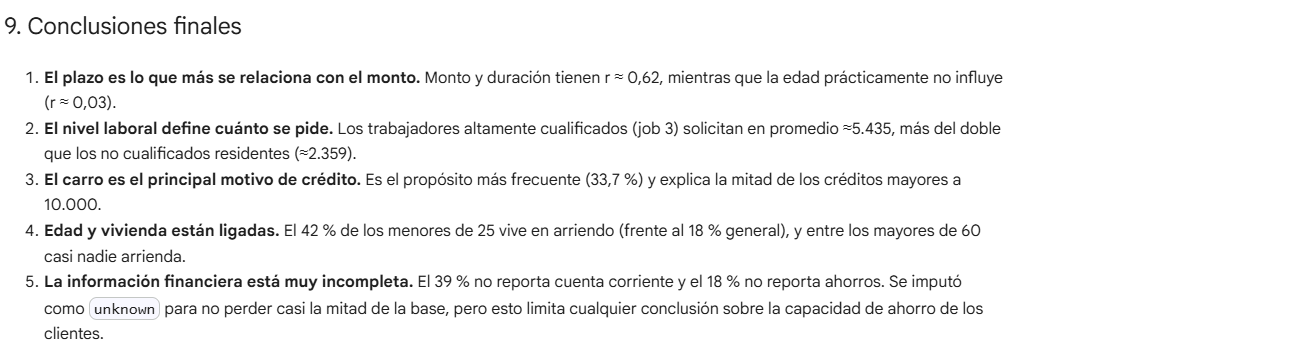